<a href="https://colab.research.google.com/github/hamzaburak16/-license-plate-detection/blob/main/PlakaTahmin_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import zipfile
with zipfile.ZipFile('/content/drive/MyDrive/YOLO_TXT.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/plaka_dataset')

In [3]:
import os

for ana_klasor, alt_klasor, dosyalar in os.walk("/content/plaka_dataset"):
    print(ana_klasor, alt_klasor, dosyalar)

/content/plaka_dataset ['images', 'labels'] ['classes.txt']
/content/plaka_dataset/images ['test', 'train', 'valid'] []
/content/plaka_dataset/images/test [] ['751.jpg', '252.jpg', '1907.jpg', '433.jpg', '1713.jpg', '1707.jpg', '821.jpg', '412.jpg', '110.jpg', '31.jpg', '415.jpg', '808.jpg', '446.jpg', '867.jpg', '638.jpg', '1270.jpg', '1087.jpg', '1789.jpg', '563.jpg', '1445.jpg', '537.jpg', '1814.jpg', '231.jpg', '1285.jpg', '484.jpg', '1074.jpg', '208.jpg', '601.jpg', '877.jpg', '1154.jpg', '1260.jpg', '619.jpg', '792.jpg', '1778.jpg', '1237.jpg', '187.jpg', '854.jpg', '1190.jpg', '1381.jpg', '21.jpg', '1850.jpg', '705.jpg', '194.jpg', '1432.jpg', '329.jpg', '1492.jpg', '1067.jpg', '732.jpg', '939.jpg', '996.jpg', '92.jpg', '973.jpg', '1177.jpg', '856.jpg', '646.jpg', '190.jpg', '1476.jpg', '1541.jpg', '1775.jpg', '115.jpg', '1568.jpg', '647.jpg', '603.jpg', '656.jpg', '1944.jpg', '1891.jpg', '69.jpg', '1703.jpg', '1539.jpg', '435.jpg', '1169.jpg', '366.jpg', '262.jpg', '1155.jpg', 

In [4]:
with open("/content/plaka_dataset/classes.txt") as dosya:
    icerik = dosya.read()
    print(icerik)

Siyah araba
Araba plakası
Arka stop lambası (sol)
Arka stop lambası (sağ)
Ford logosu
Fiesta yazısı
Arka cam
Arka silecek
Arka tampon
Sol arka tekerlek
Sağ arka tekerlek
Çakıllı zemin
class_0


In [5]:
with open("/content/plaka_dataset/labels/train/1782.txt") as dosya:
  icerik = dosya.read()
  print(icerik)

12 0.432234 0.856707 0.281042 0.077050


In [6]:
%%writefile /content/plaka_dataset/data.yaml

Writing /content/plaka_dataset/data.yaml


In [7]:
yaml_content = """
train: /content/plaka_dataset/images/train
val: /content/plaka_dataset/images/valid
nc: 1
names: ["plaka"]
"""

with open("/content/plaka_dataset/data.yaml", "w") as f:
    f.write(yaml_content)

print("data.yaml güncellendi!")

data.yaml güncellendi!


In [8]:
import os
dosyalar = os.listdir("/content/plaka_dataset/labels/train")
print(dosyalar)

['120.txt', '1954.txt', '1483.txt', '1621.txt', '1411.txt', '250.txt', '1390.txt', '420.txt', '527.txt', '950.txt', '869.txt', '1241.txt', '495.txt', '1566.txt', '1819.txt', '7.txt', '1337.txt', '1322.txt', '25.txt', '890.txt', '1442.txt', '72.txt', '848.txt', '1303.txt', '1119.txt', '84.txt', '628.txt', '1710.txt', '1812.txt', '923.txt', '1858.txt', '1024.txt', '916.txt', '801.txt', '1385.txt', '1009.txt', '1095.txt', '993.txt', '432.txt', '734.txt', '1522.txt', '1415.txt', '662.txt', '1887.txt', '623.txt', '22.txt', '1683.txt', '735.txt', '1398.txt', '707.txt', '505.txt', '1631.txt', '813.txt', '417.txt', '501.txt', '1424.txt', '351.txt', '1669.txt', '30.txt', '1681.txt', '688.txt', '424.txt', '100.txt', '1400.txt', '1395.txt', '384.txt', '1646.txt', '1277.txt', '1758.txt', '1848.txt', '1546.txt', '831.txt', '1058.txt', '222.txt', '1855.txt', '401.txt', '1810.txt', '286.txt', '1757.txt', '1344.txt', '523.txt', '1932.txt', '1283.txt', '423.txt', '708.txt', '108.txt', '1852.txt', '610.

In [9]:
with open("/content/plaka_dataset/labels/train/1024.txt") as dosya:
    satirlar = dosya.readlines()
    print(satirlar)

['12 0.535787 0.596109 0.143292 0.041232']


In [10]:
satir = satirlar[0]
print(satir)

12 0.535787 0.596109 0.143292 0.041232


In [11]:
parcalar = satir.split()
print(parcalar)
# python boşlukları anlayamadığı için üstteki çıktıyı tek metin sanar
# biz split kullandığımızda bu çıktılar ayrılır ve python bu sefer ayrı olduğunu anlar

['12', '0.535787', '0.596109', '0.143292', '0.041232']


In [12]:
sinif_id = parcalar[0]
print(sinif_id)

12


In [13]:
sinif_id = int(sinif_id)
print(sinif_id)

12


1. Dosyayı aç, satırları oku
2. Her satırı parçalara ayır
3. İlk parçayı (sınıf ID) al
4. Sayıya çevir

bunu tüm dosyalara uygulayıp,
 her sınıftan kaç tane geçtiğini sayacağız.

In [14]:
sayac = {}

In [15]:
for dosya_adi in dosyalar:
    with open("/content/plaka_dataset/labels/train/" + dosya_adi) as dosya:
        satirlar = dosya.readlines()
        for satir in satirlar:
            parcalar = satir.split()
            sinif_id = int(parcalar[0])

            if sinif_id in sayac:
                sayac[sinif_id] = sayac[sinif_id] + 1
            else:
                sayac[sinif_id] = 1

print(sayac)

{12: 1440}


In [16]:
print(len(dosyalar))

1362


In [17]:
with open("/content/plaka_dataset/labels/train/407.txt") as dosya:
    print(dosya.readlines())

with open("/content/plaka_dataset/labels/train/710.txt") as dosya:
    print(dosya.readlines())

['12 0.398761 0.399535 0.606272 0.099884']
['12 0.499614 0.534688 0.096904 0.023154']


In [18]:
print(len(dosyalar))

1362


In [19]:
with open("/content/plaka_dataset/labels/valid/52.txt") as dosya:
    print(dosya.readlines())

['12 0.461191 0.422335 0.189327 0.023107']


In [20]:
with open("/content/plaka_dataset/labels/test/430.txt") as dosya:
    print(dosya.readlines())

['12 0.495042 0.353020 0.447496 0.060729']


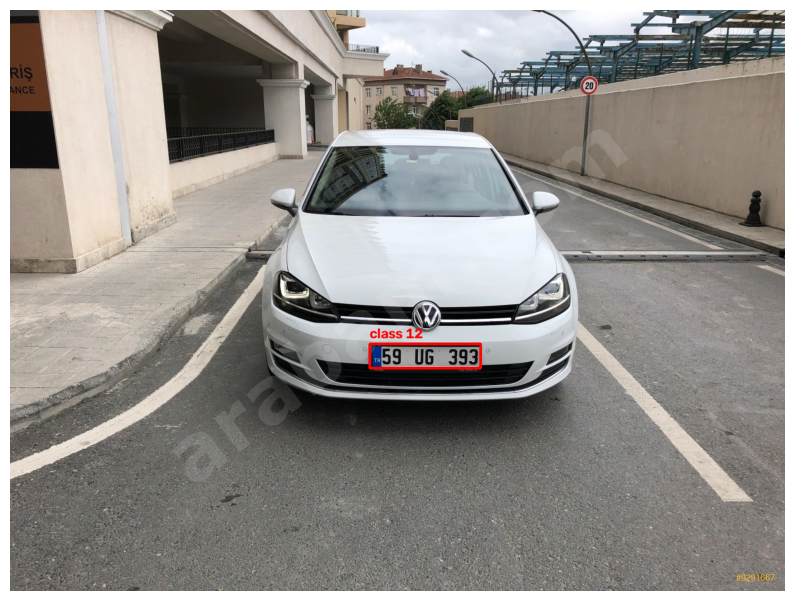

In [21]:
import cv2
import matplotlib.pyplot as plt

# Görüntüyü oku
img = cv2.imread("/content/plaka_dataset/images/train/1024.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # renkleri düzeltmek için

# Görüntünün boyutlarını al
h, w, _ = img.shape

# Etiket dosyasını oku
with open("/content/plaka_dataset/labels/train/1024.txt") as dosya:
    satirlar = dosya.readlines()

for satir in satirlar:
    parcalar = satir.split()
    sinif_id = int(parcalar[0])
    x_merkez = float(parcalar[1])
    y_merkez = float(parcalar[2])
    genislik = float(parcalar[3])
    yukseklik = float(parcalar[4])

    # Normalize koordinatları gerçek piksel koordinatlarına çevir
    x_merkez_px = x_merkez * w
    y_merkez_px = y_merkez * h
    genislik_px = genislik * w
    yukseklik_px = yukseklik * h

    x1 = int(x_merkez_px - genislik_px / 2)
    y1 = int(y_merkez_px - yukseklik_px / 2)
    x2 = int(x_merkez_px + genislik_px / 2)
    y2 = int(y_merkez_px + yukseklik_px / 2)

    # Kutuyu çiz
    cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 3)
    cv2.putText(img, f"class {sinif_id}", (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 0, 0), 2)

# Görüntüyü göster
plt.figure(figsize=(10, 10))
plt.imshow(img)
plt.axis('off')
plt.show()

In [22]:
# 1. Dosyayı aç ve satırları oku
with open("/content/plaka_dataset/labels/train/1024.txt") as dosya:
    satirlar = dosya.readlines()

print("Değişmeden önce:", satirlar)

# 2. Her satırdaki ilk sayıyı (12) 0 yap
yeni_satirlar = []
for satir in satirlar:
    parcalar = satir.split()
    parcalar[0] = "0"
    yeni_satir = " ".join(parcalar)
    yeni_satirlar.append(yeni_satir)

print("Değiştikten sonra:", yeni_satirlar)

# 3. Değişen satırları dosyanın üzerine yaz
with open("/content/plaka_dataset/labels/train/1024.txt", "w") as dosya:
    for satir in yeni_satirlar:
        dosya.write(satir + "\n")

print("Dosya güncellendi!")

Değişmeden önce: ['12 0.535787 0.596109 0.143292 0.041232']
Değiştikten sonra: ['0 0.535787 0.596109 0.143292 0.041232']
Dosya güncellendi!


In [23]:
with open("/content/plaka_dataset/labels/train/1024.txt") as dosya:
    print(dosya.readlines())

['0 0.535787 0.596109 0.143292 0.041232\n']


In [24]:
import os

klasorler = ["train", "valid", "test"]

for klasor in klasorler:
    klasor_yolu = "/content/plaka_dataset/labels/" + klasor
    dosyalar = os.listdir(klasor_yolu)

    for dosya_adi in dosyalar:
        dosya_yolu = klasor_yolu + "/" + dosya_adi

        # Oku
        with open(dosya_yolu) as dosya:
            satirlar = dosya.readlines()

        # Değiştir
        yeni_satirlar = []
        for satir in satirlar:
            parcalar = satir.split()
            parcalar[0] = "0"
            yeni_satir = " ".join(parcalar)
            yeni_satirlar.append(yeni_satir)

        # Yaz
        with open(dosya_yolu, "w") as dosya:
            for satir in yeni_satirlar:
                dosya.write(satir + "\n")

print("Tüm dosyalar güncellendi!")

Tüm dosyalar güncellendi!


In [25]:
with open("/content/plaka_dataset/labels/valid/52.txt") as dosya:
    print(dosya.readlines())

with open("/content/plaka_dataset/labels/test/430.txt") as dosya:
    print(dosya.readlines())

['0 0.461191 0.422335 0.189327 0.023107\n']
['0 0.495042 0.353020 0.447496 0.060729\n']


In [26]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 30.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [27]:
from ultralytics import YOLO

model = YOLO('yolov8n.pt')

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [28]:
model = YOLO('/content/drive/MyDrive/best_plaka_model.pt')


image 1/1 /content/plaka_dataset/images/test/6.jpg: 640x384 1 plaka, 8.6ms
Speed: 83.1ms preprocess, 8.6ms inference, 32.5ms postprocess per image at shape (1, 3, 640, 384)


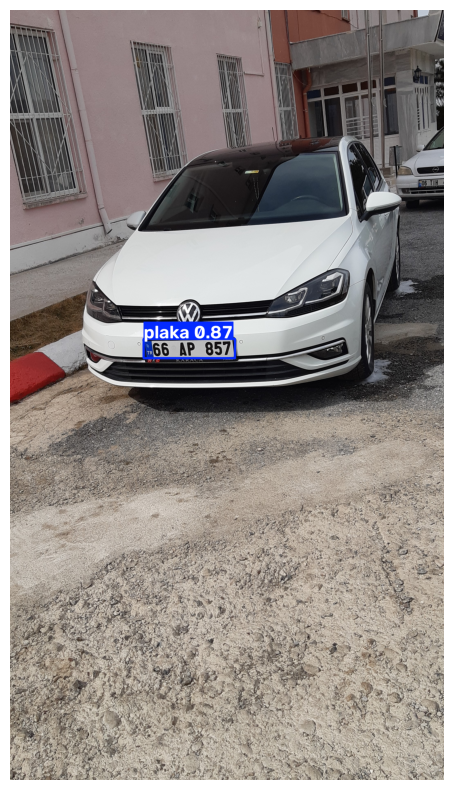

In [29]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# En iyi modeli yükle
model = YOLO('/content/drive/MyDrive/best_plaka_model.pt')

# Test için bir görüntü seç (valid veya test klasöründen)
sonuc = model('/content/plaka_dataset/images/test/6.jpg')

# Sonucu görselleştir
img_with_boxes = sonuc[0].plot()  # kutuları çizilmiş görüntüyü döndürür
img_with_boxes = cv2.cvtColor(img_with_boxes, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 10))
plt.imshow(img_with_boxes)
plt.axis('off')
plt.show()

In [30]:
!pip install easyocr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 61.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 61.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [easyocr]


Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete
image 1/1 /content/plaka_dataset/images/test/6.jpg: 640x384 1 plaka, 15.0ms
Speed: 2.8ms preprocess, 15.0ms inference, 4.0ms postprocess per image at shape (1, 3, 640, 384)


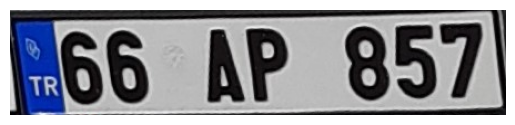

Okunan yazı: TR (güven: 0.99)
Okunan yazı: 66 (güven: 1.00)
Okunan yazı: AP (güven: 0.99)
Okunan yazı: 857 (güven: 1.00)


In [31]:
import cv2
import easyocr
import matplotlib.pyplot as plt

reader = easyocr.Reader(['en'])

img_path = '/content/plaka_dataset/images/test/6.jpg'
sonuc = model(img_path)

img = cv2.imread(img_path)

for r in sonuc:
    for box in r.boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0])
        plaka_img = img[y1:y2, x1:x2]

        plaka_rgb = cv2.cvtColor(plaka_img, cv2.COLOR_BGR2RGB)
        plt.imshow(plaka_rgb)
        plt.axis('off')
        plt.show()

        ocr_sonuc = reader.readtext(plaka_img)
        for (bbox, text, guven) in ocr_sonuc:
            print(f"Okunan yazı: {text} (güven: {guven:.2f})")

In [32]:
plaka_parcalari = []

for (bbox, text, guven) in ocr_sonuc:
    if text != "TR":
        plaka_parcalari.append(text)

plaka_metni = " ".join(plaka_parcalari)
print("Tespit edilen plaka:", plaka_metni)

Tespit edilen plaka: 66 AP 857


In [33]:
def plaka_oku(img_path):
    # Tespit yap
    sonuc = model(img_path)
    img = cv2.imread(img_path)

    plakalar = []

    for r in sonuc:
        for box in r.boxes:
            x1, y1, x2, y2 = map(int, box.xyxy[0])
            plaka_img = img[y1:y2, x1:x2]

            ocr_sonuc = reader.readtext(plaka_img)

            plaka_parcalari = []
            for (bbox, text, guven) in ocr_sonuc:
                if text != "TR":
                    plaka_parcalari.append(text)

            plaka_metni = " ".join(plaka_parcalari)
            plakalar.append(plaka_metni)

    return plakalar

In [34]:
sonuc = plaka_oku('/content/plaka_dataset/images/test/6.jpg')
print(sonuc)


image 1/1 /content/plaka_dataset/images/test/6.jpg: 640x384 1 plaka, 11.6ms
Speed: 12.8ms preprocess, 11.6ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 384)
['66 AP 857']


In [35]:
def plaka_oku(img_path):
    sonuc = model(img_path)
    img = cv2.imread(img_path)

    plakalar = []

    for r in sonuc:
        for box in r.boxes:
            x1, y1, x2, y2 = map(int, box.xyxy[0])
            plaka_img = img[y1:y2, x1:x2]

            ocr_sonuc = reader.readtext(plaka_img)

            plaka_parcalari = []
            for (bbox, text, guven) in ocr_sonuc:
                text_temiz = text.upper().strip()
                if not text_temiz.startswith("TR"):
                    plaka_parcalari.append(text_temiz)

            plaka_metni = " ".join(plaka_parcalari)
            plakalar.append(plaka_metni)

    return plakalar

In [36]:
import re

def plaka_oku(img_path):
    sonuc = model(img_path)
    img = cv2.imread(img_path)

    plakalar = []

    for r in sonuc:
        for box in r.boxes:
            x1, y1, x2, y2 = map(int, box.xyxy[0])
            plaka_img = img[y1:y2, x1:x2]

            ocr_sonuc = reader.readtext(plaka_img)

            plaka_parcalari = []
            for (bbox, text, guven) in ocr_sonuc:
                text_temiz = text.upper().strip()
                text_temiz = re.sub(r'[^A-Z0-9\s]', '', text_temiz)
                if text_temiz and not text_temiz.startswith("TR"):
                    plaka_parcalari.append(text_temiz)

            ham_metin = " ".join(plaka_parcalari)
            ham_metin = re.sub(r'\s+', ' ', ham_metin).strip()

            # Boşluksuz hali üzerinde plaka kalıbını ara
            boslukusuz = ham_metin.replace(" ", "")
            plaka_kalibi = re.search(r'\d{2}[A-Z]{1,3}\d{2,4}', boslukusuz)

            if plaka_kalibi:
                plakalar.append(plaka_kalibi.group())
            else:
                plakalar.append(ham_metin)  # kalıba uymuyorsa ham halini döndür

    return plakalar

In [37]:
import os

test_klasoru = '/content/plaka_dataset/images/test'
tum_dosyalar = os.listdir(test_klasoru)

# İlk 5 görüntüyü dene
for dosya_adi in tum_dosyalar[:5]:
    img_path = os.path.join(test_klasoru, dosya_adi)
    sonuc = plaka_oku(img_path)
    print(f"{dosya_adi} -> {sonuc}")


image 1/1 /content/plaka_dataset/images/test/751.jpg: 640x640 1 plaka, 89.8ms
Speed: 4.3ms preprocess, 89.8ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)
751.jpg -> ['66KN220']

image 1/1 /content/plaka_dataset/images/test/252.jpg: 640x384 1 plaka, 12.2ms
Speed: 2.5ms preprocess, 12.2ms inference, 2.4ms postprocess per image at shape (1, 3, 640, 384)
252.jpg -> ['38PD369']

image 1/1 /content/plaka_dataset/images/test/1907.jpg: 480x640 1 plaka, 58.4ms
Speed: 2.5ms preprocess, 58.4ms inference, 2.7ms postprocess per image at shape (1, 3, 480, 640)
1907.jpg -> ['65DB533']

image 1/1 /content/plaka_dataset/images/test/433.jpg: 640x384 1 plaka, 9.5ms
Speed: 2.1ms preprocess, 9.5ms inference, 1.3ms postprocess per image at shape (1, 3, 640, 384)
433.jpg -> ['06ET8266']

image 1/1 /content/plaka_dataset/images/test/1713.jpg: 640x480 1 plaka, 55.2ms
Speed: 2.8ms preprocess, 55.2ms inference, 9.8ms postprocess per image at shape (1, 3, 640, 480)
1713.jpg -> ['BL 0Z 1652']

In [38]:
import os

test_klasoru = '/content/plaka_dataset/images/test'
tum_dosyalar = os.listdir(test_klasoru)

sonuclar = []

for dosya_adi in tum_dosyalar:
    img_path = os.path.join(test_klasoru, dosya_adi)
    try:
        sonuc = plaka_oku(img_path)
        sonuclar.append((dosya_adi, sonuc))
    except Exception as e:
        sonuclar.append((dosya_adi, f"HATA: {e}"))

for dosya_adi, sonuc in sonuclar:
    print(f"{dosya_adi} -> {sonuc}")


image 1/1 /content/plaka_dataset/images/test/751.jpg: 640x640 1 plaka, 19.4ms
Speed: 7.5ms preprocess, 19.4ms inference, 2.1ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/plaka_dataset/images/test/252.jpg: 640x384 1 plaka, 18.2ms
Speed: 5.1ms preprocess, 18.2ms inference, 3.4ms postprocess per image at shape (1, 3, 640, 384)

image 1/1 /content/plaka_dataset/images/test/1907.jpg: 480x640 1 plaka, 10.1ms
Speed: 2.4ms preprocess, 10.1ms inference, 5.4ms postprocess per image at shape (1, 3, 480, 640)

image 1/1 /content/plaka_dataset/images/test/433.jpg: 640x384 1 plaka, 25.7ms
Speed: 5.4ms preprocess, 25.7ms inference, 6.1ms postprocess per image at shape (1, 3, 640, 384)

image 1/1 /content/plaka_dataset/images/test/1713.jpg: 640x480 1 plaka, 29.3ms
Speed: 4.7ms preprocess, 29.3ms inference, 10.3ms postprocess per image at shape (1, 3, 640, 480)

image 1/1 /content/plaka_dataset/images/test/1707.jpg: 480x640 1 plaka, 14.6ms
Speed: 6.5ms preprocess, 14.6ms infer

In [39]:
!pip install gradio

In [40]:
import gradio as gr
import numpy as np
import cv2
import re

def harf_rakam_duzelt(metin):
    degisim_harften_rakama = {'B': '3', 'O': '0', 'I': '1', 'S': '5', 'Z': '2'}

    if len(metin) < 3:
        return metin

    il_kodu = metin[:2]
    il_kodu_duzeltilmis = ""
    for karakter in il_kodu:
        if karakter in degisim_harften_rakama:
            il_kodu_duzeltilmis += degisim_harften_rakama[karakter]
        else:
            il_kodu_duzeltilmis += karakter

    return il_kodu_duzeltilmis + metin[2:]


def plaka_iyilestir(plaka_img):
    yukseklik, genislik = plaka_img.shape[:2]

    if genislik < 150:
        buyutulmus = cv2.resize(plaka_img, None, fx=3, fy=3, interpolation=cv2.INTER_CUBIC)
        gri = cv2.cvtColor(buyutulmus, cv2.COLOR_BGR2GRAY)
        kontrastli = cv2.equalizeHist(gri)
        sonuc = cv2.cvtColor(kontrastli, cv2.COLOR_GRAY2BGR)
        return sonuc
    else:
        return plaka_img


def gradio_plaka_oku(img):
    img_bgr = cv2.cvtColor(img, cv2.COLOR_RGB2BGR)

    sonuc = model(img_bgr)

    plakalar = []
    debug_metinleri = []
    kesilen_goruntu_debug = None
    sonuc_img = img_bgr.copy()

    for r in sonuc:
        for box in r.boxes:
            x1, y1, x2, y2 = map(int, box.xyxy[0])
            plaka_img = img_bgr[y1:y2, x1:x2]

            cv2.rectangle(sonuc_img, (x1, y1), (x2, y2), (255, 0, 0), 3)

            plaka_img_iyilestirilmis = plaka_iyilestir(plaka_img)

            if kesilen_goruntu_debug is None:
                kesilen_goruntu_debug = cv2.cvtColor(plaka_img_iyilestirilmis, cv2.COLOR_BGR2RGB)

            ocr_sonuc = reader.readtext(plaka_img_iyilestirilmis, allowlist='0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ')

            debug_metin = str([(text, round(guven, 2)) for (bbox, text, guven) in ocr_sonuc])
            debug_metinleri.append(debug_metin)

            plaka_parcalari = []
            for (bbox, text, guven) in ocr_sonuc:
                text_temiz = text.upper().strip()
                text_temiz = re.sub(r'[^A-Z0-9\s]', '', text_temiz)
                if text_temiz and not text_temiz.startswith("TR"):
                    plaka_parcalari.append(text_temiz)

            ham_metin = " ".join(plaka_parcalari)
            ham_metin = re.sub(r'\s+', ' ', ham_metin).strip()

            boslukusuz = ham_metin.replace(" ", "")
            boslukusuz_duzeltilmis = harf_rakam_duzelt(boslukusuz)

            plaka_kalibi = re.search(r'\d{2}[A-Z]{1,3}\d{2,4}', boslukusuz_duzeltilmis)

            if plaka_kalibi:
                plakalar.append(plaka_kalibi.group())
            else:
                plakalar.append(ham_metin)

    sonuc_img_rgb = cv2.cvtColor(sonuc_img, cv2.COLOR_BGR2RGB)

    if plakalar:
        metin_sonuc = "\n".join(plakalar)
    else:
        metin_sonuc = "Plaka bulunamadı"

    debug_sonuc = "\n".join(debug_metinleri)

    return sonuc_img_rgb, metin_sonuc, debug_sonuc, kesilen_goruntu_debug

In [41]:
arayuz = gr.Interface(
    fn=gradio_plaka_oku,
    inputs=gr.Image(type="numpy", label="Araç Fotoğrafı Yükle"),
    outputs=[
        gr.Image(type="numpy", label="Tespit Sonucu"),
        gr.Textbox(label="Okunan Plaka(lar)"),
        gr.Textbox(label="OCR Ham Sonucu (Debug)"),
        gr.Image(type="numpy", label="OCR'a Giden Görüntü (Debug)")
    ],
    title="Türk Plaka Tanıma Sistemi",
    description="Bir araç fotoğrafı yükleyin, plaka otomatik tespit edilip okunacak."
)

arayuz.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6aade5540a1017655a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)



image 1/1 /content/plaka_dataset/images/test/464.jpg: 640x640 2 plakas, 14.4ms
Speed: 4.1ms preprocess, 14.4ms inference, 2.1ms postprocess per image at shape (1, 3, 640, 640)


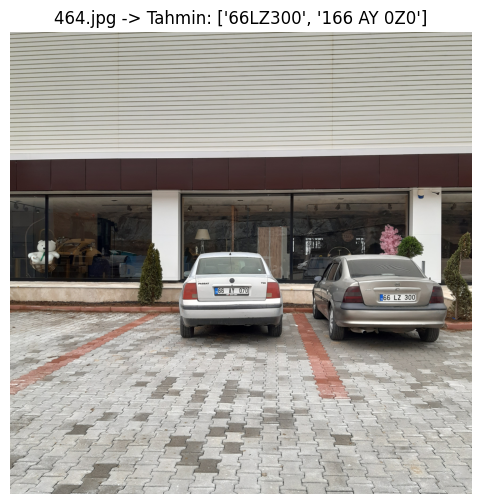


image 1/1 /content/plaka_dataset/images/test/877.jpg: 640x640 1 plaka, 12.0ms
Speed: 3.2ms preprocess, 12.0ms inference, 2.0ms postprocess per image at shape (1, 3, 640, 640)


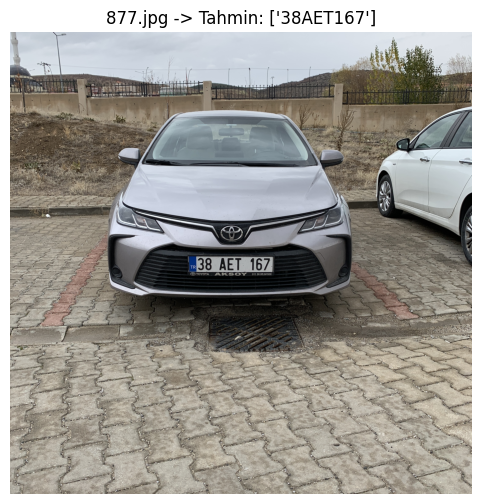


image 1/1 /content/plaka_dataset/images/test/821.jpg: 640x640 1 plaka, 12.0ms
Speed: 3.1ms preprocess, 12.0ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 640)


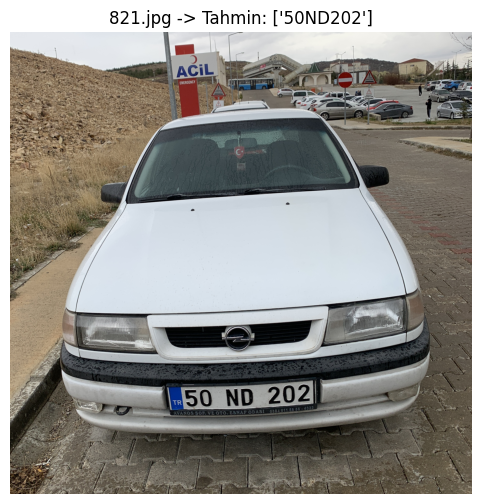


image 1/1 /content/plaka_dataset/images/test/1490.jpg: 640x480 1 plaka, 14.4ms
Speed: 2.2ms preprocess, 14.4ms inference, 2.9ms postprocess per image at shape (1, 3, 640, 480)


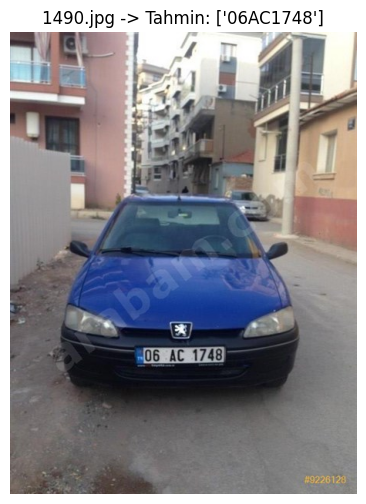


image 1/1 /content/plaka_dataset/images/test/1169.jpg: 480x640 1 plaka, 12.0ms
Speed: 2.6ms preprocess, 12.0ms inference, 2.0ms postprocess per image at shape (1, 3, 480, 640)


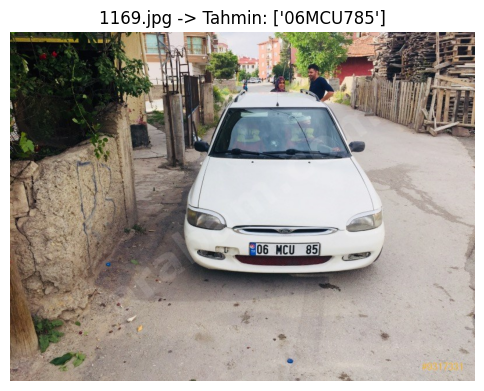


image 1/1 /content/plaka_dataset/images/test/603.jpg: 640x640 1 plaka, 11.1ms
Speed: 3.4ms preprocess, 11.1ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 640)


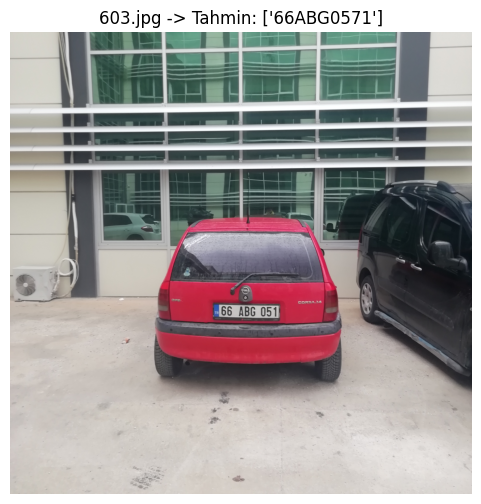


image 1/1 /content/plaka_dataset/images/test/1541.jpg: 384x640 1 plaka, 12.6ms
Speed: 3.4ms preprocess, 12.6ms inference, 2.0ms postprocess per image at shape (1, 3, 384, 640)


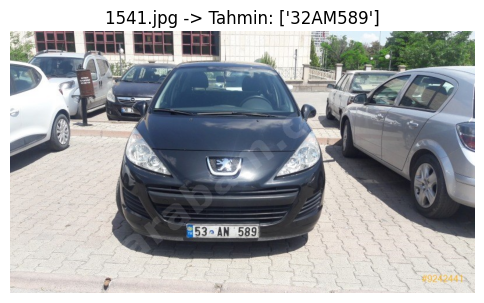


image 1/1 /content/plaka_dataset/images/test/187.jpg: 640x384 1 plaka, 11.1ms
Speed: 3.4ms preprocess, 11.1ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 384)


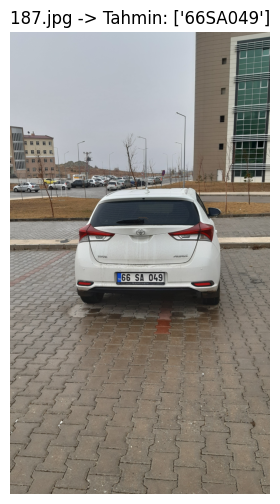


image 1/1 /content/plaka_dataset/images/test/1911.jpg: 480x640 1 plaka, 14.5ms
Speed: 2.8ms preprocess, 14.5ms inference, 3.1ms postprocess per image at shape (1, 3, 480, 640)


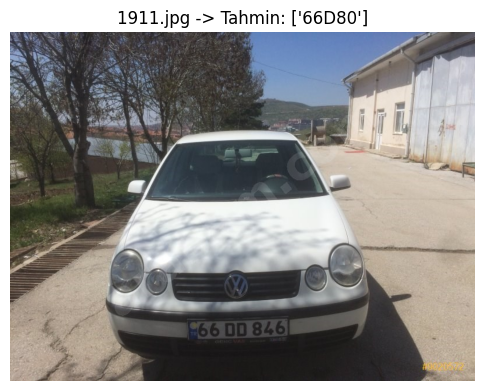


image 1/1 /content/plaka_dataset/images/test/208.jpg: 640x384 1 plaka, 10.6ms
Speed: 2.6ms preprocess, 10.6ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 384)


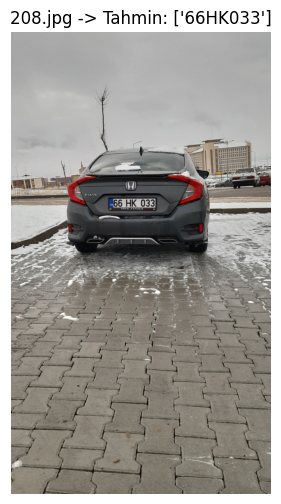


image 1/1 /content/plaka_dataset/images/test/88.jpg: 640x384 1 plaka, 10.9ms
Speed: 3.1ms preprocess, 10.9ms inference, 2.4ms postprocess per image at shape (1, 3, 640, 384)


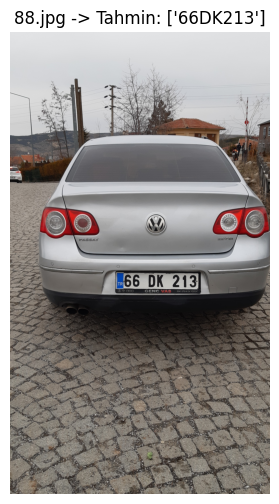


image 1/1 /content/plaka_dataset/images/test/1750.jpg: 640x352 1 plaka, 12.9ms
Speed: 2.0ms preprocess, 12.9ms inference, 2.0ms postprocess per image at shape (1, 3, 640, 352)


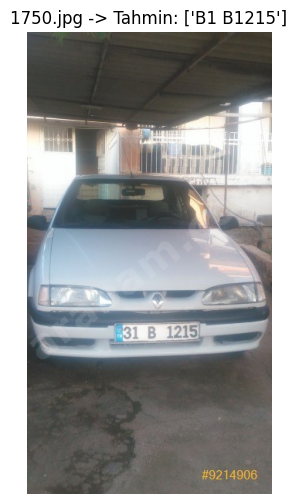


image 1/1 /content/plaka_dataset/images/test/231.jpg: 640x384 1 plaka, 11.7ms
Speed: 3.1ms preprocess, 11.7ms inference, 2.3ms postprocess per image at shape (1, 3, 640, 384)


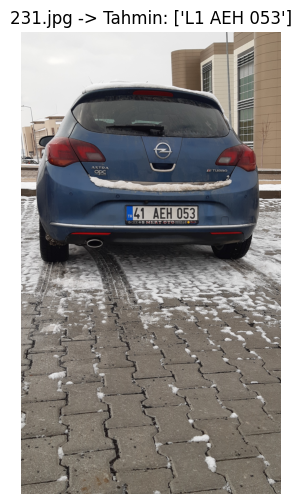


image 1/1 /content/plaka_dataset/images/test/1504.jpg: 384x640 1 plaka, 12.5ms
Speed: 2.2ms preprocess, 12.5ms inference, 2.0ms postprocess per image at shape (1, 3, 384, 640)


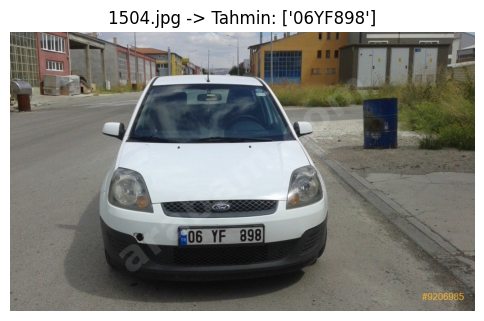


image 1/1 /content/plaka_dataset/images/test/1935.jpg: 384x640 1 plaka, 11.2ms
Speed: 2.9ms preprocess, 11.2ms inference, 2.3ms postprocess per image at shape (1, 3, 384, 640)


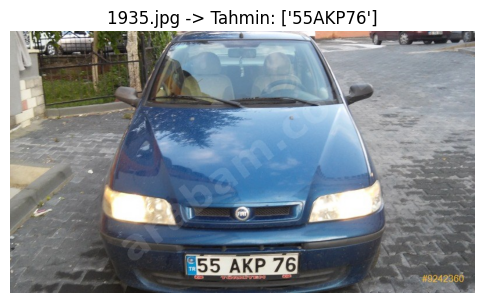


image 1/1 /content/plaka_dataset/images/test/110.jpg: 640x384 1 plaka, 11.5ms
Speed: 4.0ms preprocess, 11.5ms inference, 1.8ms postprocess per image at shape (1, 3, 640, 384)


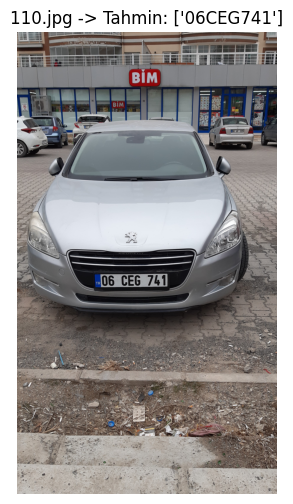


image 1/1 /content/plaka_dataset/images/test/412.jpg: 640x384 1 plaka, 10.6ms
Speed: 3.3ms preprocess, 10.6ms inference, 2.0ms postprocess per image at shape (1, 3, 640, 384)


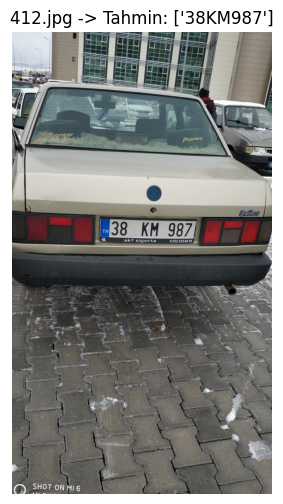


image 1/1 /content/plaka_dataset/images/test/1285.jpg: 480x640 1 plaka, 18.2ms
Speed: 4.6ms preprocess, 18.2ms inference, 1.9ms postprocess per image at shape (1, 3, 480, 640)


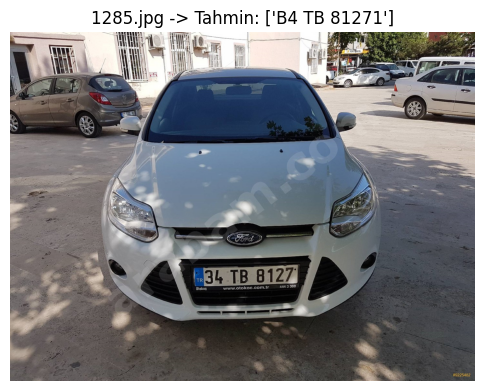


image 1/1 /content/plaka_dataset/images/test/190.jpg: 640x384 1 plaka, 13.0ms
Speed: 2.9ms preprocess, 13.0ms inference, 2.1ms postprocess per image at shape (1, 3, 640, 384)


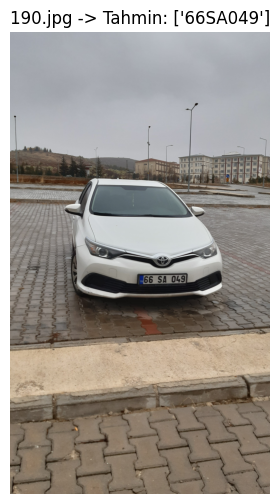


image 1/1 /content/plaka_dataset/images/test/115.jpg: 640x384 1 plaka, 36.0ms
Speed: 5.0ms preprocess, 36.0ms inference, 10.8ms postprocess per image at shape (1, 3, 640, 384)


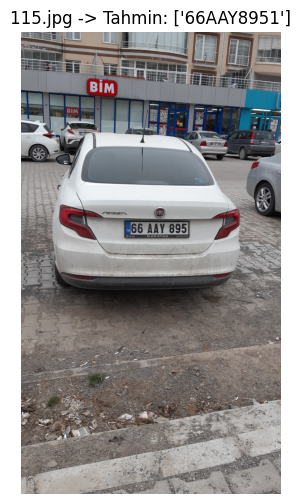

In [42]:
import random
import matplotlib.pyplot as plt

test_klasoru = '/content/plaka_dataset/images/test'
tum_dosyalar = os.listdir(test_klasoru)

# Rastgele 20 görüntü seç
random.seed(42)  # aynı sonucu tekrar görebilmek için sabit bir tohum
secilen_dosyalar = random.sample(tum_dosyalar, 20)

for dosya_adi in secilen_dosyalar:
    img_path = os.path.join(test_klasoru, dosya_adi)

    sonuc = plaka_oku(img_path)

    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(6, 6))
    plt.imshow(img_rgb)
    plt.title(f"{dosya_adi} -> Tahmin: {sonuc}")
    plt.axis('off')
    plt.show()

In [ ]:
import os
import re

klasorler = ['train', 'valid', 'test']

toplam_gorsel = 0
format_uyan = 0
format_uymayan = []

turk_plaka_kalibi = re.compile(r'^\d{2}[A-Z]{1,3}\d{2,4}$')

for klasor in klasorler:
    resim_klasoru = f'/content/plaka_dataset/images/{klasor}'
    dosyalar = os.listdir(resim_klasoru)

    for dosya_adi in dosyalar:
        img_path = os.path.join(resim_klasoru, dosya_adi)
        toplam_gorsel += 1

        try:
            sonuclar = plaka_oku(img_path)
        except Exception as e:
            format_uymayan.append((klasor, dosya_adi, f"HATA: {e}"))
            continue

        if not sonuclar:
            format_uymayan.append((klasor, dosya_adi, "Plaka bulunamadı"))
            continue

        # İlk bulunan plakayı kontrol et
        ilk_sonuc = sonuclar[0].replace(" ", "")

        if turk_plaka_kalibi.match(ilk_sonuc):
            format_uyan += 1
        else:
            format_uymayan.append((klasor, dosya_adi, sonuclar))

print(f"Toplam görüntü: {toplam_gorsel}")
print(f"Formata uyan: {format_uyan}")
print(f"Formata uymayan: {len(format_uymayan)}")
print(f"Oran: {format_uyan / toplam_gorsel * 100:.1f}%")


image 1/1 /content/plaka_dataset/images/train/1287.jpg: 640x480 1 plaka, 14.0ms
Speed: 2.7ms preprocess, 14.0ms inference, 3.1ms postprocess per image at shape (1, 3, 640, 480)

image 1/1 /content/plaka_dataset/images/train/763.jpg: 640x640 1 plaka, 13.2ms
Speed: 3.6ms preprocess, 13.2ms inference, 1.7ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/plaka_dataset/images/train/900.jpg: 640x640 1 plaka, 11.9ms
Speed: 3.1ms preprocess, 11.9ms inference, 2.0ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/plaka_dataset/images/train/680.jpg: 640x640 4 plakas, 12.0ms
Speed: 3.1ms preprocess, 12.0ms inference, 2.5ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/plaka_dataset/images/train/1021.jpg: 640x480 1 plaka, 12.2ms
Speed: 2.1ms preprocess, 12.2ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 480)

image 1/1 /content/plaka_dataset/images/train/466.jpg: 640x640 1 plaka, 11.6ms
Speed: 3.5ms preprocess, 11.6ms 

In [ ]:
plaka_bulunamadi_sayisi = sum(1 for (k, d, s) in format_uymayan if s == "Plaka bulunamadı")
ocr_hatasi_sayisi = len(format_uymayan) - plaka_bulunamadi_sayisi

print(f"Plaka bulunamadı: {plaka_bulunamadi_sayisi}")
print(f"OCR formatı bozuk: {ocr_hatasi_sayisi}")